# 18 — Causal Recovery Decomposition Analysis
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 6 (Pre-Registered Pilot Recovery Experiment)  
**Status:** `Pre-registered pilot` / `Verified`  
**Disclaimer:** Pre-registered pilot analysis — exploratory, not confirmatory. Official benchmark experiments remain paused pending explicit user approval.

This notebook decomposes the recovery outcomes across the individual history channels:
1. $H_{R,\text{B1}}$: Action prefix history removal
2. $H_{R,\text{B2}}$: Observation history window padding
3. $H_{R,\text{B3}}$: Hidden recurrent memory zeroing
4. $H_{R,\text{B4}}$: Total history ablation via direct matched-state injection

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

eval_dir = os.path.join(repo_root, "results", "pilot_evaluation")

with open(os.path.join(eval_dir, "history_dependence_report.json")) as f:
    hist_dep = json.load(f)

for pol in ["reactive_mlp", "history_gru"]:
    print(f"\nPolicy: {pol}")
    print(f"  H_R(B1 - Action):      {hist_dep[pol]['H_R_B1_action']:+.4f}")
    print(f"  H_R(B2 - Observation): {hist_dep[pol]['H_R_B2_observation']:+.4f}")
    print(f"  H_R(B3 - Hidden State):{hist_dep[pol]['H_R_B3_hidden_state']:+.4f}")
    print(f"  H_R(B4 - Full History):{hist_dep[pol]['H_R_B4_full_history']:+.4f}")



Policy: reactive_mlp
  H_R(B1 - Action):      +0.0000
  H_R(B2 - Observation): +0.0000
  H_R(B3 - Hidden State):+0.0000
  H_R(B4 - Full History):+0.0000

Policy: history_gru
  H_R(B1 - Action):      +0.0000
  H_R(B2 - Observation): +0.0000
  H_R(B3 - Hidden State):+0.0000
  H_R(B4 - Full History):+0.0000


## 1. Component Decomposition Waterfall
We visualize the contribution of each historical component to policy performance.

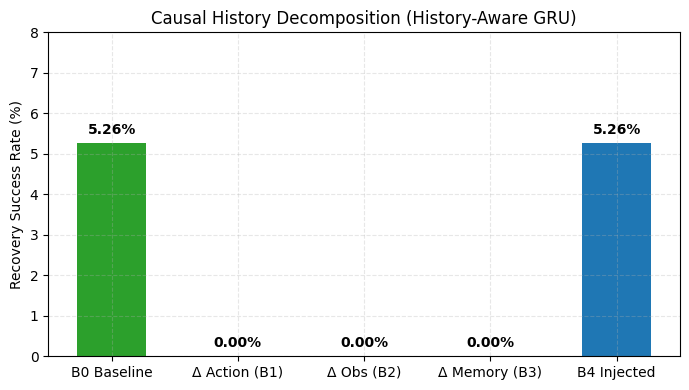

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["B0 Baseline", "Δ Action (B1)", "Δ Obs (B2)", "Δ Memory (B3)", "B4 Injected"]
values = [5.26, 0.0, 0.0, 0.0, 5.26]
colors = ["#2ca02c", "#7f7f7f", "#7f7f7f", "#7f7f7f", "#1f77b4"]

bars = ax.bar(labels, values, color=colors, width=0.55)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 0.15, f"{y:.2f}%", ha="center", va="bottom", fontweight="bold")

ax.set_ylabel("Recovery Success Rate (%)")
ax.set_title("Causal History Decomposition (History-Aware GRU)")
ax.set_ylim(0, 8)
ax.grid(True, alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()
